In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Entendimento & Preparaçãodos dados

### leitura, forma dos dados, primeiras e últimas linhas dos dados

In [2]:
caminho = r"C:\Users\User\OneDrive\Área de Trabalho\EngDados\datasets\datatran2026.csv"

df_acidentes_prf_1s26 = pd.read_csv(caminho, delimiter=';', encoding='ISO-8859-1')

# outros econdings: 'utf-8' 'latin1'

df_acidentes_prf_1s26.shape

(54895, 30)

In [3]:
df_acidentes_prf_1s26.head()

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,742921.0,2026-01-01,quinta-feira,04:04:00,TO,153,155,ARAGUAINA,Objeto estático sobre o leito carroçável,Tombamento,...,0,1,3,0,5,"-7,291548","-48,286252",SPRF-TO,DEL02-TO,UOP01-DEL02-TO
1,742942.0,2026-01-01,quinta-feira,06:40:00,MG,262,"146,1",RIO CASCA,Condutor Dormindo,Colisão frontal,...,4,1,1,4,3,"-20,0240733","-42,7422291",SPRF-MG,DEL03-MG,UOP03-DEL03-MG
2,742943.0,2026-01-01,quinta-feira,06:58:00,SC,101,193,BIGUACU,Reação tardia ou ineficiente do condutor,Colisão lateral mesmo sentido,...,0,1,2,1,4,"-27,48935222","-48,65565777",SPRF-SC,DEL01-SC,UOP01-DEL01-SC
3,742947.0,2026-01-01,quinta-feira,07:05:00,DF,60,23,BRASILIA,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,1,1,1,3,"-15,988927","-48,2263",SPRF-DF,DEL03-DF,UOP01-DEL03-DF
4,742960.0,2026-01-01,quinta-feira,06:17:00,MT,163,1044,MATUPA,Transitar na contramão,Colisão frontal,...,1,1,3,1,5,"-10,14330603","-54,93075559",SPRF-MT,DEL06-MT,UOP03-DEL06-MT


In [4]:
df_acidentes_prf_1s26.tail()

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
54890,808143.0,2026-09-27,domingo,03:00:00,RJ,101,308,SAO GONCALO,Ausência de reação do condutor,Colisão traseira,...,0,2,0,2,3,"-22,79658274","-43,03339899",SPRF-RJ,DEL02-RJ,UOP02-DEL02-RJ
54891,808159.0,2026-09-06,domingo,19:20:00,GO,60,"452,9",JATAI,Animais na Pista,Saída de leito carroçável,...,2,0,0,3,1,"-17,85941124","-51,55806351",SPRF-GO,DEL05-GO,UOP01-DEL05-GO
54892,808177.0,2026-08-16,domingo,20:20:00,MG,381,673,PERDOES,Carga excessiva e/ou mal acondicionada,Colisão com objeto,...,0,3,0,1,4,"-21,119793","-45,095585",SPRF-MG,DEL04-MG,UOP02-DEL04-MG
54893,808242.0,2026-05-16,sábado,13:00:00,MG,251,"359,5",PADRE CARVALHO,Ingestão de álcool pelo condutor,Colisão lateral sentido oposto,...,0,2,0,0,2,"-16,270926","-42,560574",SPRF-MG,DEL12-MG,UOP02-DEL12-MG
54894,808269.0,2026-09-30,quarta-feira,21:40:00,RJ,101,327,NITEROI,Ausência de reação do condutor,Colisão traseira,...,1,2,0,1,2,"-22,87070762","-43,16144367",SPRF-RJ,DEL02-RJ,UOP01-DEL02-RJ


### gerar metadados

In [5]:
def generate_metadata(dataframe):
    """
    Gera um dataframe contendo metadados das colunas do dataframe fornecido.

    :param dataframe: DataFrame para o qual os metadados serão gerados.
    :return: DataFrame contendo metadados.
    """

    # Coleta de metadados básicos
    metadata = pd.DataFrame({
        'nome_variavel': dataframe.columns,
        'tipo': dataframe.dtypes.astype(str),
        'qt_nulos': dataframe.isnull().sum(),
        'percent_nulos': round((dataframe.isnull().sum() / len(dataframe))* 100,2),
        'cardinalidade': dataframe.nunique()
    })
    
    metadata = metadata.sort_values(by="tipo")
    metadata = metadata.reset_index(drop=True)

    return metadata

In [6]:
metadata_df = generate_metadata(df_acidentes_prf_1s26)
metadata_df

,nome_variavel,tipo,qt_nulos,percent_nulos,cardinalidade
0,id,float64,0,0.00,54895
1,br,int64,0,0.00,112
2,pessoas,int64,0,0.00,58
3,mortos,int64,0,0.00,13
4,feridos_leves,int64,0,0.00,30
5,feridos_graves,int64,0,0.00,18
6,ilesos,int64,0,0.00,52
7,ignorados,int64,0,0.00,17
8,feridos,int64,0,0.00,37
9,veiculos,int64,0,0.00,19


### Tratamentos de nulos e faltantes

In [7]:
# a base tem poucos nulos e somente em variáveis string

# Análise Descritiva

In [8]:
df_acidentes_prf_1s26.describe()

,id,br,pessoas,mortos,feridos_leves,feridos_graves,ilesos,ignorados,feridos,veiculos
count,54895.000000,54895.000000,54895.000000,54895.000000,54895.000000,54895.000000,54895.000000,54895.000000,54895.000000,54895.000000
mean,773356.789034,210.620730,2.623554,0.083979,0.874123,0.273176,1.082102,0.398488,1.147299,2.006030
std,17415.768136,129.060032,2.263066,0.356915,1.072432,0.620062,1.834586,0.827930,1.199997,1.103763
min,742884.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,758312.500000,101.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
50%,773453.000000,163.000000,2.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,2.000000
75%,788475.500000,324.000000,3.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,2.000000
max,808269.000000,495.000000,88.000000,23.000000,45.000000,27.000000,85.000000,18.000000,48.000000,19.000000


In [9]:
df_acidentes_prf_1s26.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,54895.0,NaN,NaN,NaN,773356.789034,17415.768136,742884.0,758312.5,773453.0,788475.5,808269.0
data_inversa,54895,273,2026-09-05,319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dia_semana,54895,7,domingo,8740,NaN,NaN,NaN,NaN,NaN,NaN,NaN
horario,54895,1407,19:00:00,811,NaN,NaN,NaN,NaN,NaN,NaN,NaN
uf,54895,27,MG,7132,NaN,NaN,NaN,NaN,NaN,NaN,NaN
br,54895.0,NaN,NaN,NaN,210.62073,129.060032,0.0,101.0,163.0,324.0,495.0
km,54895,6999,0,242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
municipio,54895,1823,BRASILIA,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN
causa_acidente,54895,69,Ausência de reação do condutor,8778,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_acidente,54895,17,Colisão traseira,11073,NaN,NaN,NaN,NaN,NaN,NaN,NaN


* Quantidade de Observações: Existem 54895.0 registros no conjunto de dados. Isso indica o número total de ocorrências nas rodovias federias no primeiro semestre de 2026.
* Valores Nulos: Existem pouquíssimos valores nulos ou faltantes, demonstrando uma base de dados bem íntegra.
* Incidentes por Dia: O dia com mais incidentes é o "domingo" (8.740 registros), o que pode indicar que os finais de semana têm uma frequência mais alta de ocorrências.
* Localização dos Incidentes: A maioria dos incidentes ocorre em Minas Gerais (MG), com 7.132 registros.
* Causa mais Comum: A causa mais frequente de incidentes é a "Ausência de reação do condutor", ocorrendo 8.778 vezes.
* Tipo de Acidente mais Comum: A "Colisão traseira" é o tipo mais comum de acidente, ocorrendo 11.073 vezes.
* Quantidade de Veículos Envolvidos: Em média, cada incidente envolve aproximadamente 2 veículos.
* Vítimas: A média de feridos por incidente é de 1,15, com um máximo de 48 feridos em um único incidente. Além disso, a média de feridos graves por incidente é de 0,27 aproximadamente.
* Distribuição de Incidentes ao Longo do Semestre: O dia com o maior número de incidentes registrados é "2026-09-05", com 319 ocorrências.
* Diversidade de Causas e Tipos: Há 69 causas diferentes de acidentes e 17 tipos diferentes de acidentes listados no conjunto de dados.

# Análises

### Box Plot (Distribuição dos dados)

In [10]:
def pod_academy_box_plot(dataframe):
    """
    Plota boxplots estilizados com título simplificado para todas as variáveis numéricas do dataframe fornecido
    em um painel com 3 gráficos por linha.

    :param dataframe: DataFrame para o qual os boxplots serão gerados.
    """
    # Seleciona apenas colunas numéricas
    numeric_columns = dataframe.select_dtypes(include=['float64', 'int64']).columns

    # Define o número de linhas com base no número de colunas numéricas
    nrows = len(numeric_columns) // 3 + (len(numeric_columns) % 3 > 0)

    # Inicializa o painel de gráficos
    fig, axes = plt.subplots(nrows=nrows, ncols=3, figsize=(15, nrows * 5))

    # Ajusta o layout
    plt.tight_layout(pad=5)

    # Configura estilo e paleta de cores
    sns.set_style("whitegrid")

    # Plota boxplots para cada coluna numérica
    for i, column in enumerate(numeric_columns):
        sns.boxplot(data=dataframe[column], ax=axes[i//3, i%3], color="skyblue")
        axes[i//3, i%3].set_title(f'{column}', fontdict={'fontsize': 14, 'fontweight': 'bold'})
        axes[i//3, i%3].set_ylabel('')
        axes[i//3, i%3].tick_params(axis='both', which='major', labelsize=12)

    # Remove gráficos vazios (se houver)
    for j in range(i+1, nrows*3):
        fig.delaxes(axes.flatten()[j])

    # Adiciona título principal
    fig.suptitle("Análise descritiva - BoxPlot", fontsize=20, fontweight='bold', y=1.05)

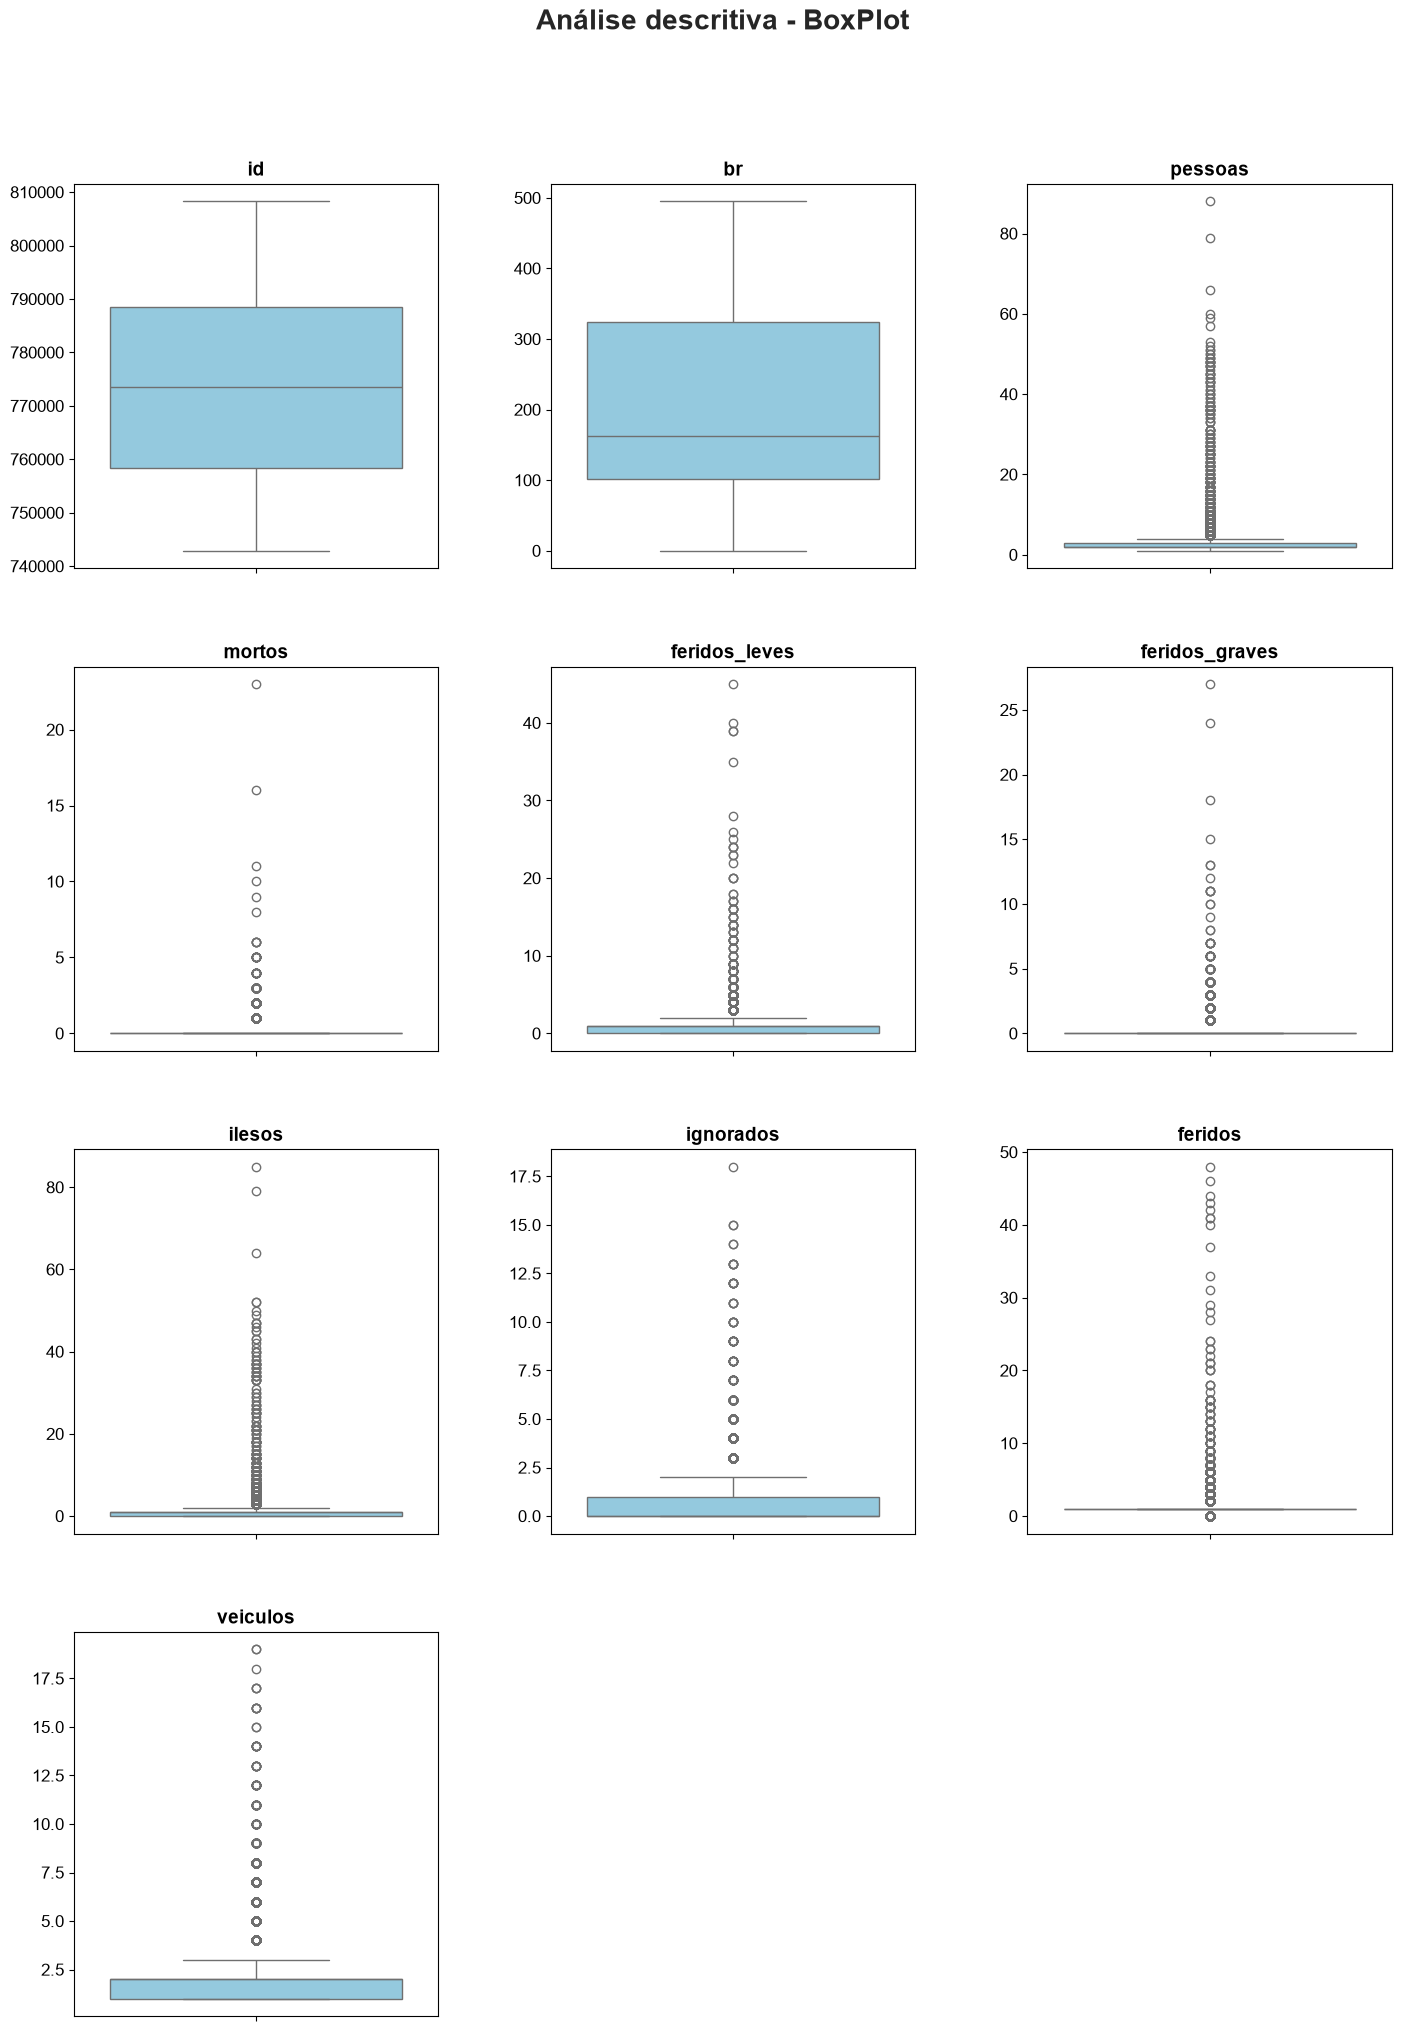

In [11]:
# Plotando os boxplots estilizados com títulos simplificados usando a função definida
pod_academy_box_plot(df_acidentes_prf_1s26)

**Variabilidade e Distribuição:**
* Variáveis como pessoas, mortos, feridos_leves, feridos_graves, ilesos, ignorados e feridos têm a maioria de seus valores concentrados perto de zero, indicando que muitos incidentes envolvem poucas pessoas ou nenhuma vítima. No entanto, existem alguns valores atipicamente altos para estas variáveis, sugerindo que, embora raros, existem incidentes com um número significativo de envolvidos ou vítimas.

**Outliers:**
* Muitas das variáveis apresentam outliers. Estes são pontos que caem fora das "antenas" do boxplot e podem indicar valores atipicamente altos ou baixos. Por exemplo, a variável pessoas tem vários valores que são consideravelmente mais altos do que a mediana, sugerindo incidentes com um número anormalmente alto de pessoas envolvidas. Os outliers podem indicar tanto erros de entrada de dados quanto eventos reais que são atípicos. Eles podem ser investigados mais a fundo para entender sua natureza.

**Concentração de Dados:**
* A linha central do box (mediana) para variáveis como mortos, feridos_leves, feridos_graves, ilesos e feridos está no valor zero. Isso indica que a maioria dos incidentes não resulta em mortes ou ferimentos.

**Amplitude dos Dados:**
* O intervalo interquartil (IQR), que é a altura da caixa no boxplot, indica onde reside a metade central dos dados. Para muitas das variáveis, o IQR é pequeno, mostrando que os valores estão concentrados. Por outro lado, uma caixa maior indica maior variabilidade nos dados.

**Tendências e Anomalias:**
* Se os dados estivessem distribuídos em grupos ou categorias (como diferentes estados ou tipos de incidentes), poderíamos usar boxplots para comparar essas categorias e identificar tendências ou anomalias específicas de cada grupo. Estes são insights gerais que podem ser obtidos a partir dos boxplots. Para insights mais específicos ou detalhados, seria útil combinar a análise visual dos boxplots com outras técnicas estatísticas e métodos de visualização.

### Histograma (frequência dos intervalos - bins)

In [12]:
def pod_academy_histograms(dataframe):
    """
    Plota histogramas corrigidos com a curva KDE (Kernel Density Estimation) para todas as variáveis numéricas
    do dataframe fornecido em um painel com 3 gráficos por linha.

    :param dataframe: DataFrame para o qual os histogramas serão gerados.
    """
    # Seleciona apenas colunas numéricas
    numeric_columns = dataframe.select_dtypes(include=['float64', 'int64']).columns

    # Define o número de linhas com base no número de colunas numéricas
    nrows = len(numeric_columns) // 3 + (len(numeric_columns) % 3 > 0)

    # Inicializa o painel de gráficos
    fig, axes = plt.subplots(nrows=nrows, ncols=3, figsize=(15, nrows * 5))

    # Ajusta o layout
    plt.tight_layout(pad=4)

    # Configura estilo e paleta de cores
    sns.set_style("whitegrid")

    # Plota histogramas com KDE para cada coluna numérica
    for i, column in enumerate(numeric_columns):
        sns.histplot(data=dataframe[column], ax=axes[i//3, i%3], color="skyblue", bins=30, kde=True)
        axes[i//3, i%3].set_title(f'{column}', fontdict={'fontsize': 14, 'fontweight': 'bold'})
        axes[i//3, i%3].set_ylabel('Frequência')
        axes[i//3, i%3].tick_params(axis='both', which='major', labelsize=12)

    # Remove gráficos vazios (se houver)
    for j in range(i+1, nrows*3):
        fig.delaxes(axes.flatten()[j])

    # Adiciona título principal
    fig.suptitle("Análise descritiva - Histograma com KDE", fontsize=20, fontweight='bold', y=1.05)

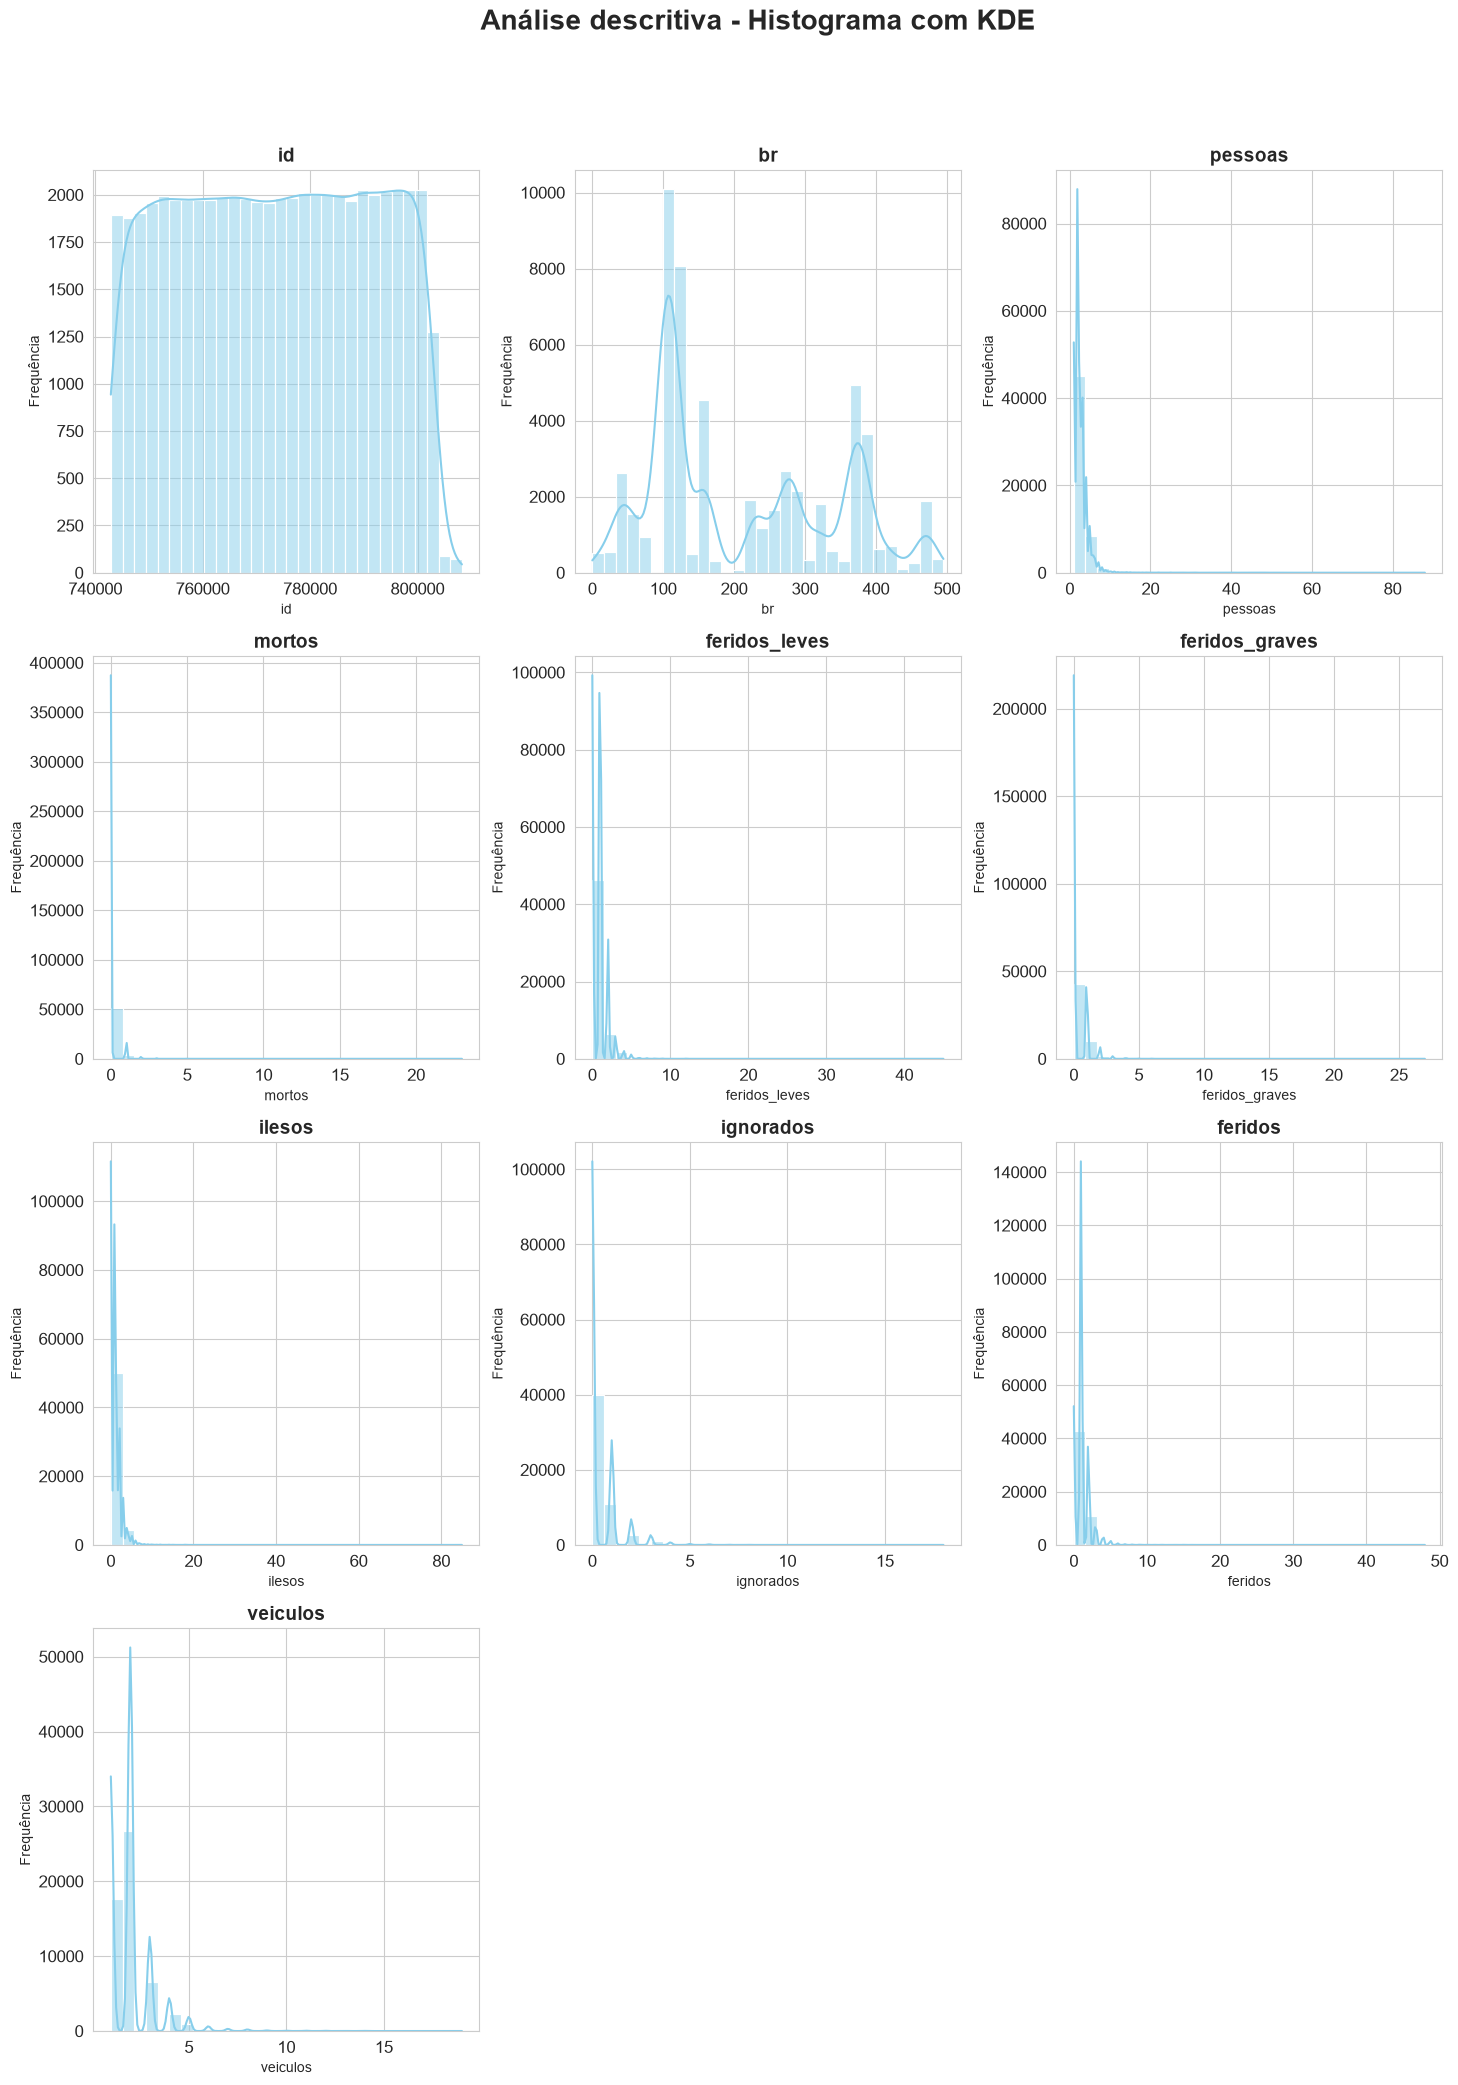

In [13]:
# Plotando os histogramas com KDE corrigidos em um painel usando a função definida
pod_academy_histograms(df_acidentes_prf_1s26)

**Distribuição**:
- Variáveis como pessoas, mortos, feridos_leves, feridos_graves, ilesos, ignorados e feridos têm a maioria de seus valores concentrados perto de zero. Isso é consistente com os boxplots.

**Modas:**
- A maioria das variáveis tem uma única moda, indicando uma distribuição unimodal. No entanto, se houvesse mais de um pico, isso indicaria uma distribuição bimodal ou multimodal.

**Assimetria:**
- Muitas das variáveis mostram uma assimetria positiva, com uma "cauda" à direita. Isso indica que a maioria dos incidentes envolve poucas pessoas ou tem poucas vítimas, mas há casos raros (outliers) com um número elevado de pessoas envolvidas ou vítimas.

**Outliers e Valores Atípicos:**
- Como os histogramas mostram a frequência de valores, é difícil identificar outliers diretamente. No entanto, a presença de uma "cauda" longa em um histograma pode indicar a presença de outliers.

**Concentração de Dados:**
- A altura das barras do histograma indica a frequência de valores. Assim, podemos ver que a maioria dos incidentes não resulta em mortes ou ferimentos graves.

### Barras (frequência de categorias)

In [14]:
def plot_categorical_frequency_pt(df, corte_cardinalidade=30, graficos_por_linha=2):
    """
    Plota a frequência de categorias para variáveis categóricas em um DataFrame.

    Parâmetros:
    - df: DataFrame para plotagem.
    - corte_cardinalidade: Cardinalidade máxima para uma coluna ser considerada (padrão é 30).
    - graficos_por_linha: Quantidade de gráficos por linha (padrão é 3).

    Retorna:
    - Exibe os gráficos de barras.
    """

    # Gera metadados para o DataFrame
    metadados = []
    for coluna in df.columns:
        metadados.append({
            'Variável': coluna,
            'Tipo': df[coluna].dtype,
            'Cardinalidade': df[coluna].nunique()
        })

    df_metadados = pd.DataFrame(metadados)

    # Filtra colunas com cardinalidade maior que o corte e tipos não numéricos
    variaveis_categoricas = df_metadados[(df_metadados['Cardinalidade'] <= corte_cardinalidade) & (df_metadados['Tipo'] == 'str')]

    # Calcula o número de linhas e colunas para os subplots
    n_linhas = -(-len(variaveis_categoricas) // graficos_por_linha)  # Ceiling division
    n_colunas = min(len(variaveis_categoricas), graficos_por_linha)

    # Plota as variáveis categóricas
    fig, axs = plt.subplots(nrows=n_linhas, ncols=n_colunas, figsize=(15, 5 * n_linhas))

    for i, (idx, linha) in enumerate(variaveis_categoricas.iterrows()):
        var = linha['Variável']
        ax = axs[i // graficos_por_linha, i % graficos_por_linha]
        df[var].value_counts().sort_index().plot(kind='bar', ax=ax, color='skyblue')
        ax.set_title(f'Frequência em {var}')
        ax.set_ylabel('Frequência')
        ax.set_xlabel(var)

    # Remove os eixos vazios, se houver
    for j in range(i + 1, n_linhas * n_colunas):
        axs[j // graficos_por_linha, j % graficos_por_linha].axis('off')

    plt.tight_layout()
    plt.show()

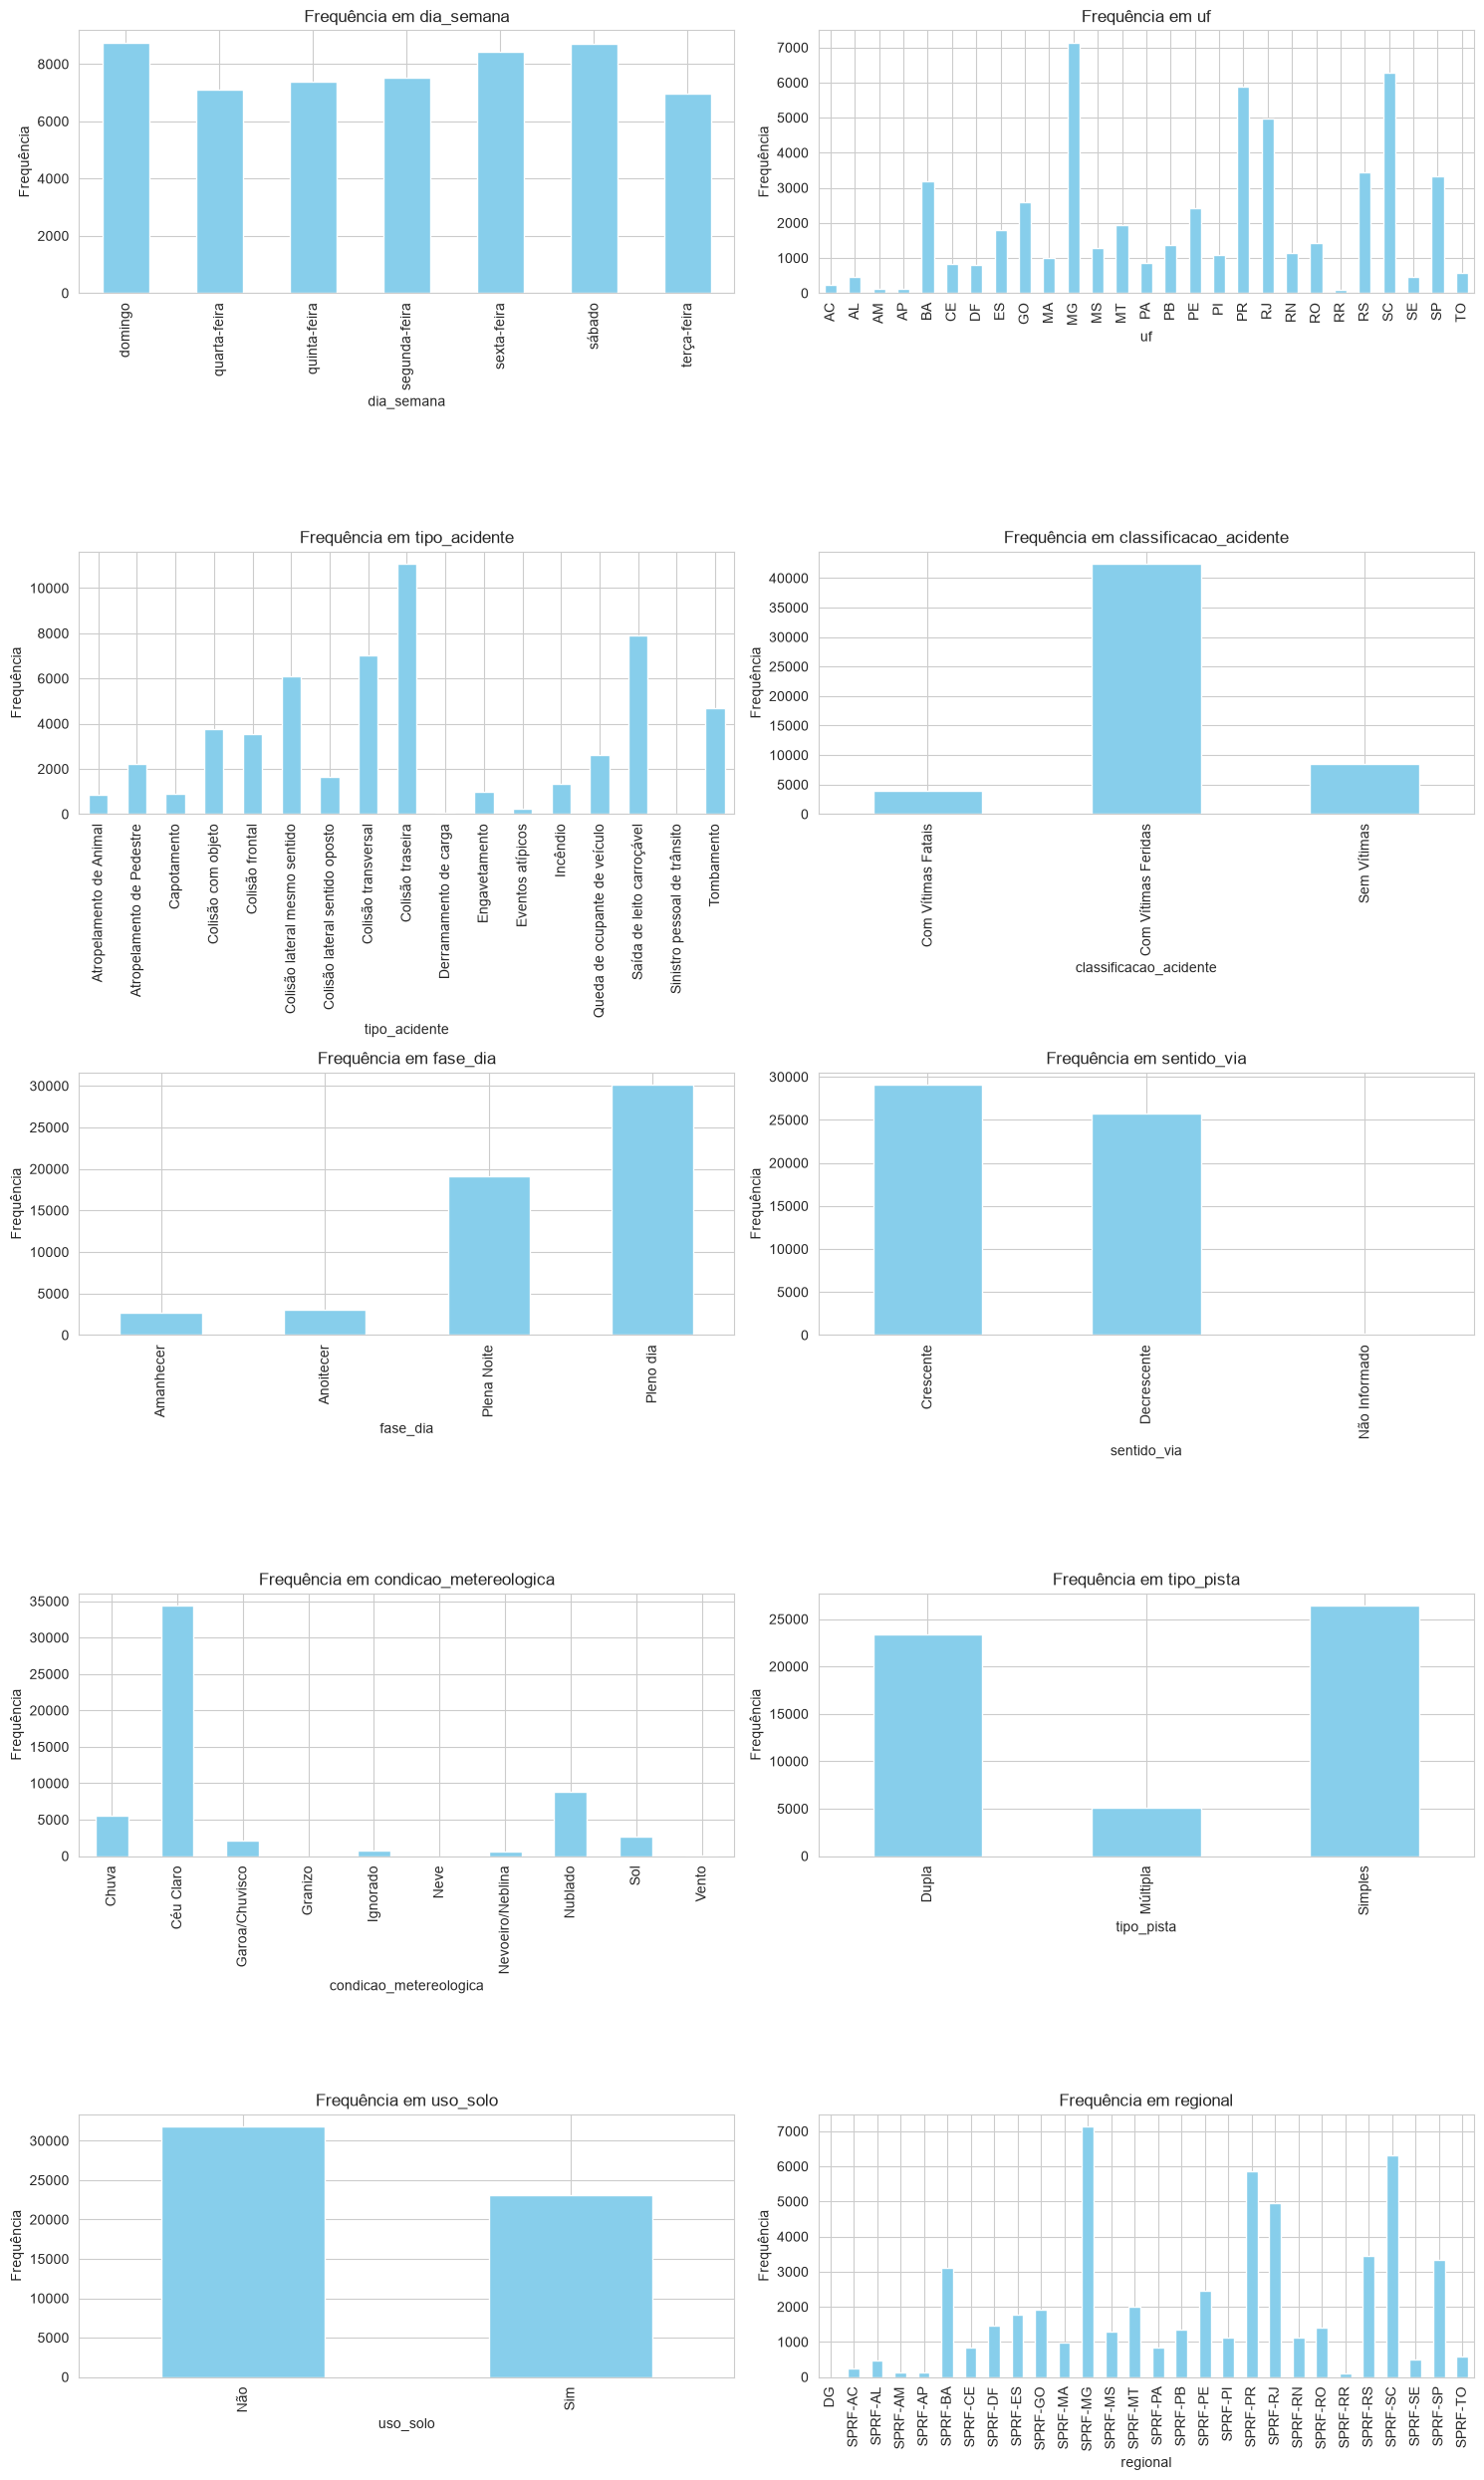

In [15]:
# Testa a função com os dados e o corte padrão de cardinalidade
plot_categorical_frequency_pt(df_acidentes_prf_1s26, corte_cardinalidade=30, graficos_por_linha=2)

**Dias da Semana (dia_semana)**:
- A maioria dos registros parece ocorrer nos finais de semana (sábado e domingo). Isso pode indicar um aumento de atividades ou eventos que resultam em mais registros nesses dias.

**UF (Estados)**:
- Alguns estados têm uma contagem mais alta de registros em comparação com outros. É essencial considerar a população e o tamanho de cada estado ao interpretar esses dados. Por exemplo, estados mais populosos ou com maiores redes rodoviárias podem naturalmente ter mais registros.

**Causa do Acidente (causa_acidente)**:
- Alguns motivos parecem ser mais predominantes que outros. Por exemplo, "Colisão traseira" e "Saída de leito carroçável" parecem ser causas comuns, o que pode indicar a necessidade de campanhas de conscientização e atenção.

**Classificação do Acidente (classificacao_acidente)**:
- A maioria dos acidentes parece ser sem vítimas ou com feridos leves, o que é uma boa notícia. No entanto, ainda há uma quantidade significativa de acidentes com feridos graves e mortos, ressaltando a importância da segurança no trânsito.

**Fase do Dia (fase_dia)**:
- Os acidentes parecem ser mais comuns durante o dia e noite. Isso pode estar relacionado às horas de pico de tráfego ou à visibilidade reduzida.

**Condição Meteorológica (condicao_metereologica)**:
- A maioria dos registros ocorre em condições claras, o que é esperado, mas também destaca que condições adversas, como chuva, não são os principais contribuintes para os acidentes, embora possam aumentar sua gravidade.

**Tipo de Pista (tipo_pista)**:
- A maioria dos registros ocorre em pistas simples, o que pode indicar que essas pistas apresentam mais riscos ou que são mais comuns nas áreas abrangidas pelos dados.

### Respondendo perguntas de negócio

#### 1. Quais são os estados com maior número de acidentes?

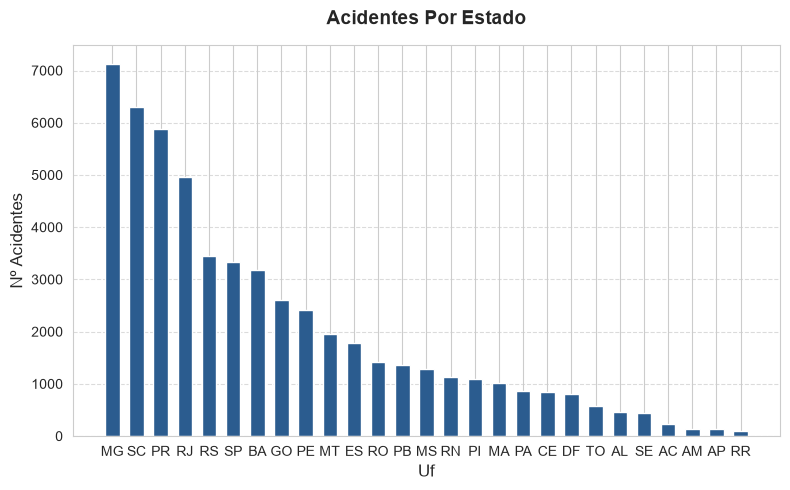

In [16]:
# Definindo os dados
contagem_por_uf = df_acidentes_prf_1s26["uf"].value_counts()

# Criando a figura e os eixos do gráfico
fig, ax = plt.subplots(figsize=(8, 5))

# Gerando o gráfico de barras
ax.bar(contagem_por_uf.index, contagem_por_uf.values, color='#2b5c8f', width=0.6)

# Configurando títulos e rótulos dos eixos
ax.set_title('Acidentes Por Estado', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Uf', fontsize=12)
ax.set_ylabel('Nº Acidentes', fontsize=12)

# Adicionando linhas de grade horizontais para facilitar a leitura
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Ajustando o layout e exibindo o gráfico
plt.tight_layout()
plt.show()

##### Os Top 4 estados com maior número de acidentes são:
* 1º Lugar: MG
* 2º Lugar: SC
* 3º Lugar: PR
* 4º Lugar: RJ

#### 2. Quais são as principais causas de acidentes?

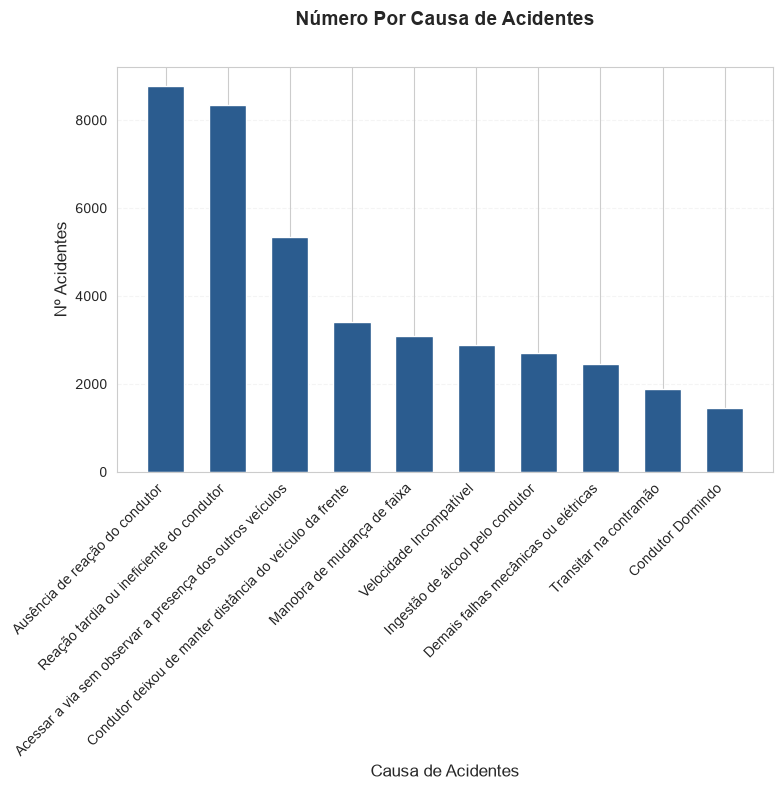

In [17]:
# Definindo os dados
contagem_por_causa_acidente = df_acidentes_prf_1s26["causa_acidente"].value_counts()

# Criando a figura e os eixos do gráfico
fig, ax = plt.subplots(figsize=(8, 8))

# Gerando o gráfico de barras
ax.bar(contagem_por_causa_acidente.iloc[:10].index, contagem_por_causa_acidente.iloc[:10].values, color='#2b5c8f', width=0.6)

# Configurando títulos e rótulos dos eixos
ax.set_title('Número Por Causa de Acidentes', fontsize=14, fontweight='bold', pad=30)
ax.set_xlabel('Causa de Acidentes', fontsize=12)
ax.set_ylabel('Nº Acidentes', fontsize=12)

# Deixando os rótulos do eixo X com 45 graus e alinha o texto perfeitamente abaixo de cada barra
plt.xticks(rotation=45, ha='right')

# Adicionando linhas de grade horizontais para facilitar a leitura
ax.grid(axis='y', linestyle='--', alpha=0.2)

# Ajustando o layout e exibindo o gráfico
plt.tight_layout()
plt.show()

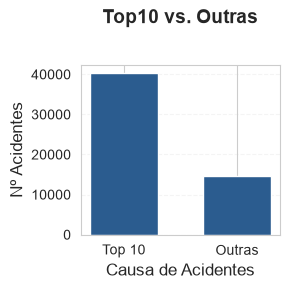

Nº acidentes Top 10 causas = 40347 | % Top 10 causas = 73.50
Nº acidentes Outras causas = 14548 | % Outras causas = 26.50


In [18]:
# Definindo os dados
top10 = contagem_por_causa_acidente.iloc[:10].sum()
outras = contagem_por_causa_acidente.iloc[10:].sum()

top10_vs_outras = {"Top 10": top10, "Outras": outras}

# Criando a figura e os eixos do gráfico
fig, ax = plt.subplots(figsize=(3, 3))

# Gerando o gráfico de barras
ax.bar(top10_vs_outras.keys(), top10_vs_outras.values(), color='#2b5c8f', width=0.6)

# Configurando títulos e rótulos dos eixos
ax.set_title('Top10 vs. Outras', fontsize=14, fontweight='bold', pad=30)
ax.set_xlabel('Causa de Acidentes', fontsize=12)
ax.set_ylabel('Nº Acidentes', fontsize=12)

# Adicionando linhas de grade horizontais para facilitar a leitura
ax.grid(axis='y', linestyle='--', alpha=0.2)

# Ajustando o layout e exibindo o gráfico
plt.tight_layout()
plt.show()

# Verificando o número relativo de cada categoria
print(f"Nº acidentes Top 10 causas = {top10} | % Top 10 causas = {(top10 / (top10 + outras))*100:.2f}")
print(f"Nº acidentes Outras causas = {outras} | % Outras causas = {(outras / (top10 + outras))*100:.2f}")

##### As 10 principais causas de acidentes são:
* 1ª Ausência de reação do condutor
* 2ª Reação tardia ou ineficiente do condutor
* 3ª Acessar a via sem observar a presença de outros veículos
* 4ª Condutor deixou de manter distância do veículo da frente
* 5ª Manobra de mudança de faixa
* 6ª Velocidade incompatível
* 7ª Ingestão de álcool pelo condutor
* 8ª Demais falhas mecânicas ou elétricas
* 9ª Transitarna contramão
* 10ª Condutor dormindo

##### Além disso:
* Essas **10 principais causas** de acidentes são responsáveis por **73,50%** de todos os acidentes (40.347)
* Enquanto as **Outras Causas** representam **26,50%** (um total de 14.548 acidentes)

#### 3. Em que dias da semana e horários ocorrem mais acidentes?

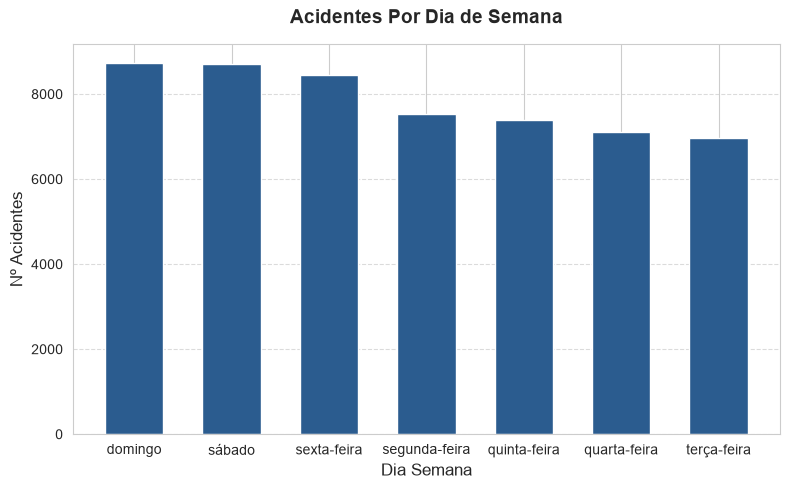

In [19]:
# Definindo os dados
contagem_por_dia_semana = df_acidentes_prf_1s26["dia_semana"].value_counts()

# Criando a figura e os eixos do gráfico
fig, ax = plt.subplots(figsize=(8, 5))

# Gerando o gráfico de barras
ax.bar(contagem_por_dia_semana.index, contagem_por_dia_semana.values, color='#2b5c8f', width=0.6)

# Configurando títulos e rótulos dos eixos
ax.set_title('Acidentes Por Dia de Semana', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Dia Semana', fontsize=12)
ax.set_ylabel('Nº Acidentes', fontsize=12)

# Adicionando linhas de grade horizontais para facilitar a leitura
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Ajustando o layout e exibindo o gráfico
plt.tight_layout()
plt.show()

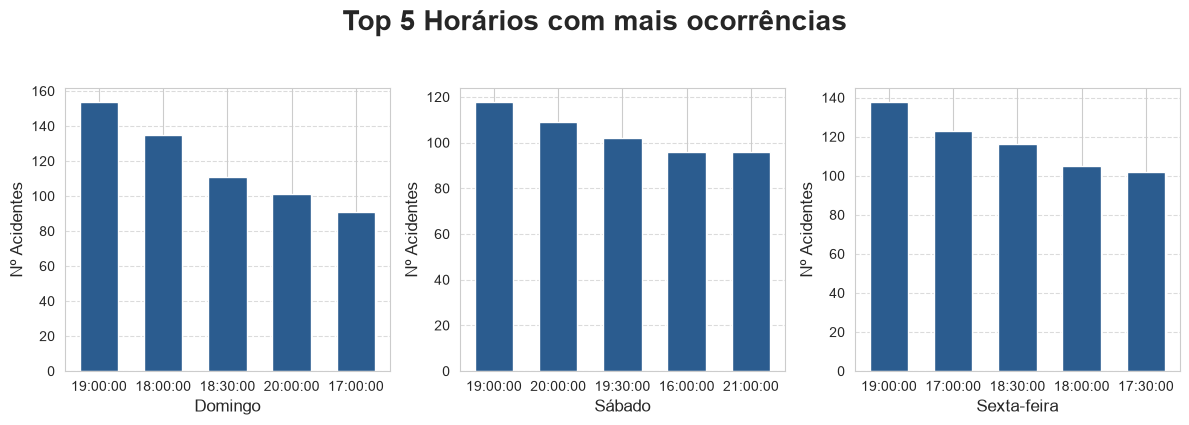

In [20]:
horarios_domingo = df_acidentes_prf_1s26[df_acidentes_prf_1s26["dia_semana"] == "domingo"]["horario"].value_counts()
horarios_sabado = df_acidentes_prf_1s26[df_acidentes_prf_1s26["dia_semana"] == "sábado"]["horario"].value_counts()
horarios_sexta = df_acidentes_prf_1s26[df_acidentes_prf_1s26["dia_semana"] == "sexta-feira"]["horario"].value_counts()

fig, ax = plt.subplots(1, 3, figsize=(12,4))

# plot domingo
ax[0].bar(horarios_domingo.iloc[:5].index, horarios_domingo.iloc[:5].values, color='#2b5c8f', width=0.6)
ax[0].set_xlabel('Domingo', fontsize=12)
ax[0].set_ylabel('Nº Acidentes', fontsize=12)
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

# plot sábado
ax[1].bar(horarios_sabado.iloc[:5].index, horarios_sabado.iloc[:5].values, color='#2b5c8f', width=0.6)
ax[1].set_xlabel('Sábado', fontsize=12)
ax[1].set_ylabel('Nº Acidentes', fontsize=12)
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

# plot sexta-feira
ax[2].bar(horarios_sexta.iloc[:5].index, horarios_sexta.iloc[:5].values, color='#2b5c8f', width=0.6)
ax[2].set_xlabel('Sexta-feira', fontsize=12)
ax[2].set_ylabel('Nº Acidentes', fontsize=12)
ax[2].grid(axis='y', linestyle='--', alpha=0.7)

fig.suptitle("Top 5 Horários com mais ocorrências", fontsize=20, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

##### Os dias da semana em que mais ocorrem acidentes são:
* Domingo
* Sábado
* Sexta-feira

##### Além disso, os horários em que mais ocorrem acidentes são:
* Das 17:00 às 20:00 no Domingo (um intervalo de 3 horas de pico no número de acidentes)
* Das 16:00 às 21:00 no Sábado (5 horas)
* Das 17:00 às 19:00 na Sexta-feira (2 horas)

#### 4. Como a condição climática influencia na ocorrência de acidentes?

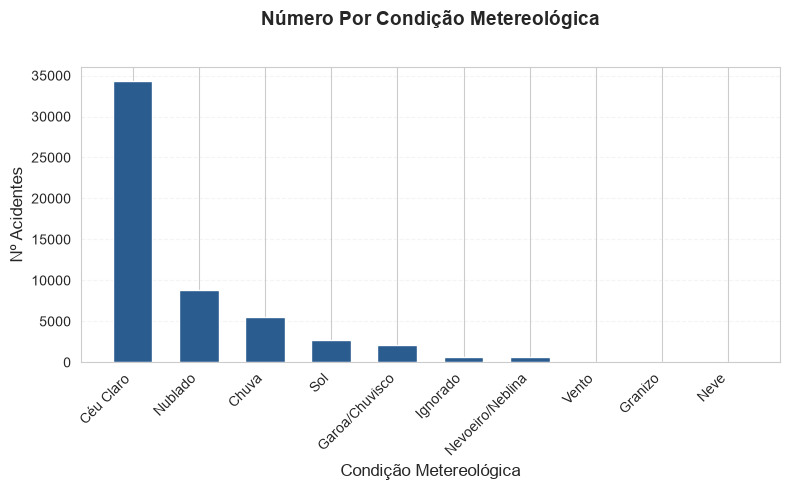

In [21]:
# Definindo os dados
contagem_por_cond_met = df_acidentes_prf_1s26["condicao_metereologica"].value_counts()

# Criando a figura e os eixos do gráfico
fig, ax = plt.subplots(figsize=(8, 5))

# Gerando o gráfico de barras
ax.bar(contagem_por_cond_met.index, contagem_por_cond_met.values, color='#2b5c8f', width=0.6)

# Configurando títulos e rótulos dos eixos
ax.set_title('Número Por Condição Metereológica', fontsize=14, fontweight='bold', pad=30)
ax.set_xlabel('Condição Metereológica', fontsize=12)
ax.set_ylabel('Nº Acidentes', fontsize=12)

# Deixando os rótulos do eixo X com 45 graus e alinha o texto perfeitamente abaixo de cada barra
plt.xticks(rotation=45, ha='right')

# Adicionando linhas de grade horizontais para facilitar a leitura
ax.grid(axis='y', linestyle='--', alpha=0.2)

# Ajustando o layout e exibindo o gráfico
plt.tight_layout()
plt.show()

##### Aqui, vemos que as condições climáticas adversas não inlfuenciam no número de acidentes.
* Pois a maior parte dos acidentes acontece sob condições de Céu Claro

#### 5. Quais são os tipos de acidentes mais comuns e suas consequências (número de mortos e feridos)?

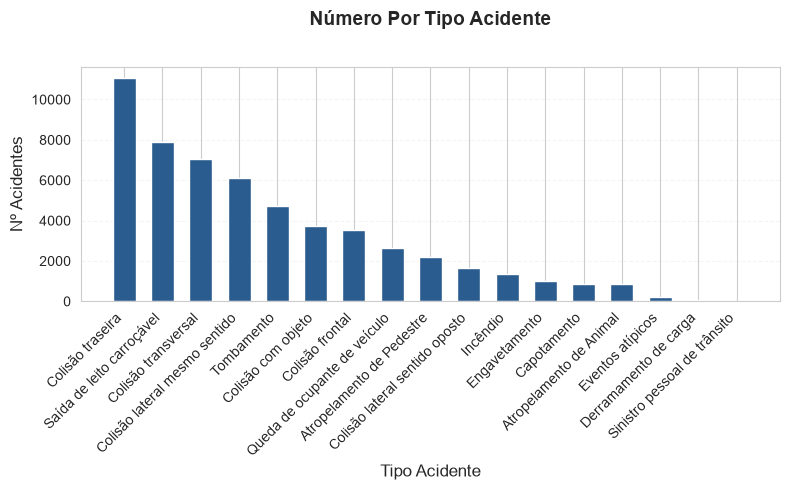

In [22]:
# Definindo os dados
contagem_por_tipo_acid = df_acidentes_prf_1s26["tipo_acidente"].value_counts()

# Criando a figura e os eixos do gráfico
fig, ax = plt.subplots(figsize=(8, 5))

# Gerando o gráfico de barras
ax.bar(contagem_por_tipo_acid.index, contagem_por_tipo_acid.values, color='#2b5c8f', width=0.6)

# Configurando títulos e rótulos dos eixos
ax.set_title('Número Por Tipo Acidente', fontsize=14, fontweight='bold', pad=30)
ax.set_xlabel('Tipo Acidente', fontsize=12)
ax.set_ylabel('Nº Acidentes', fontsize=12)

# Deixando os rótulos do eixo X com 45 graus e alinha o texto perfeitamente abaixo de cada barra
plt.xticks(rotation=45, ha='right')

# Adicionando linhas de grade horizontais para facilitar a leitura
ax.grid(axis='y', linestyle='--', alpha=0.2)

# Ajustando o layout e exibindo o gráfico
plt.tight_layout()
plt.show()

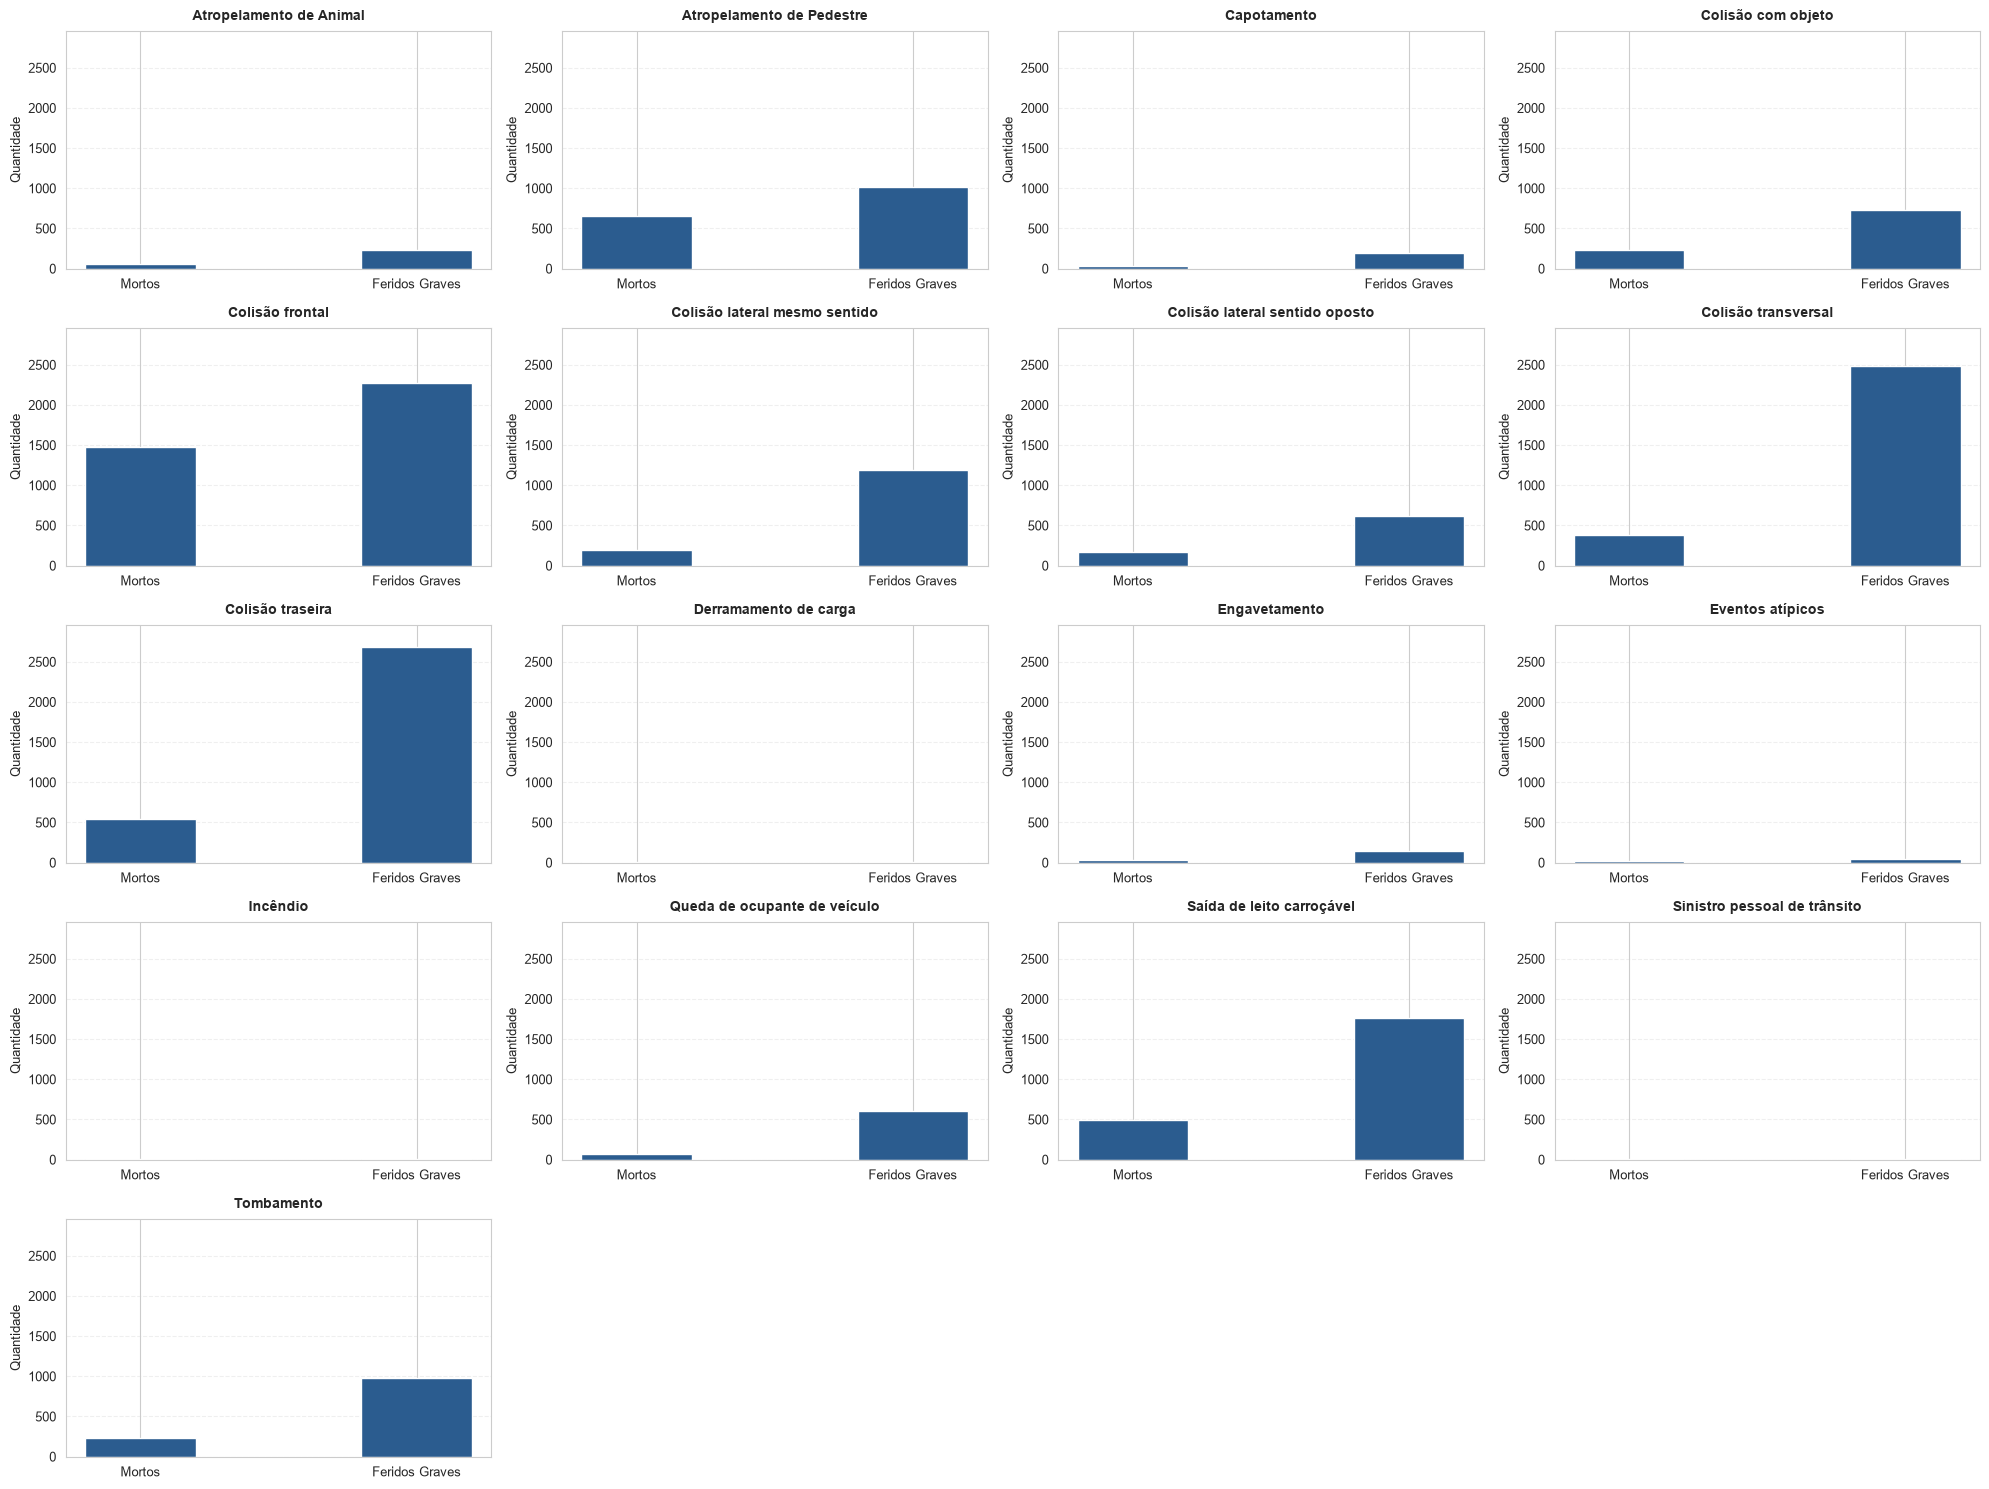

In [29]:
df_severidade_por_tipo = df_acidentes_prf_1s26.groupby("tipo_acidente")[["mortos", "feridos_graves"]].sum()

lista_tipo_acidentes = df_severidade_por_tipo.index.tolist()
total_tipos = len(lista_tipo_acidentes)

# Descobre qual é o maior número entre todas as somas de mortos e feridos graves
max_global = df_severidade_por_tipo.max().max()

n_cols = 4
n_lins = (total_tipos + n_cols - 1) // n_cols

fig, ax = plt.subplots(n_lins, n_cols, figsize=(20, 15))
ax_flat = ax.flatten() # achatando a matrix de subplots para um array

for i, tipo in enumerate(lista_tipo_acidentes):
    # calculando o número de mortos e feridos graves do tipo específico
    num_mortos = df_acidentes_prf_1s26[df_acidentes_prf_1s26["tipo_acidente"] == tipo]["mortos"].sum()
    num_feridos_graves = df_acidentes_prf_1s26[df_acidentes_prf_1s26["tipo_acidente"] == tipo]["feridos_graves"].sum()

    # Começa em 0 e vai até o maior valor global + 10% de margem (para a barra mais alta não colar no topo)
    ax_flat[i].set_ylim(0, max_global * 1.1)

    # criando o gráfico
    ax_flat[i].bar(["Mortos", "Feridos Graves"], [num_mortos, num_feridos_graves], color='#2b5c8f', width=0.4)
    ax_flat[i].set_title(f'{tipo}', fontsize=10, fontweight='bold', pad=8)
    ax_flat[i].set_ylabel('Quantidade', fontsize=9)
    ax_flat[i].grid(axis='y', linestyle='--', alpha=0.3)
    ax_flat[i].tick_params(axis='both', labelsize=9)

# Desligando os eixos dos subplots que sobraram (caso a grade seja maior que o número de tipos)
for j in range(i + 1, len(ax_flat)):
    ax_flat[j].axis('off')

plt.tight_layout()
plt.show()

In [55]:
print(df_acidentes_prf_1s26.groupby("tipo_acidente")["mortos"].sum().sort_values(ascending = False).iloc[0])
print(df_acidentes_prf_1s26.groupby("tipo_acidente")["feridos_graves"].sum().sort_values(ascending = False).iloc[0])

1481
2688


##### Os tipos de acidentes e suas consequências:
* Os Top 5 tipos de acidentes que mais acontecem nas rodovias são: Colisão traseira, Saída do leito carroçável, Colisção transversal, Colisão lateral mesmo sentido e Tombamento.
* O mais letal é tipo de acidente é a Colisão frontal, que deixou 1.481 mortes
* O tipo que mais grave sem fatalidades é a Colisão Traseira, que deixou 2.688 feridos graves